# Analiza jakości powietrza
Krzysztof Kata 254776  
Zadanie 3

Celem zadania jest analiza stężenia CO i prosta prognoza na kolejne 7 dni.

Źródło: [Air Quality — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/360/air+quality), S. Vito, 2008, DOI: 10.24432/C59K5F.
Zbiór zawiera pomiary układu czujników gazu oraz analizatora referencyjnego.
Analizowana kolumna CO(GT) podaje stężenie CO z analizatora w mg/m³.
Wartość -200 oznacza brak pomiaru.


In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

plik = "AirQualityUCI.zip"
if not Path(plik).exists():
    urlretrieve("https://archive.ics.uci.edu/static/public/360/air+quality.zip", plik)

with ZipFile(plik) as archiwum:
    dane = pd.read_csv(archiwum.open("AirQualityUCI.csv"),
                       sep=";", decimal=",", na_values=-200)
dane = dane.dropna(subset=["Date", "Time"])
dane.index = pd.to_datetime(dane["Date"] + " " + dane["Time"],
                            format="%d/%m/%Y %H.%M.%S")
dane = dane.sort_index()
co = dane["CO(GT)"].resample("D").mean()


## Analiza danych
Statystyki dotyczą pomiarów godzinowych. Wykres pokazuje średnie dzienne z dostępnych pomiarów. Dni bez odczytów pozostają puste.


Liczba pomiarów: 9357
Braki CO: 1683
mean     2.153
min      0.100
max     11.900
Name: CO(GT), dtype: float64


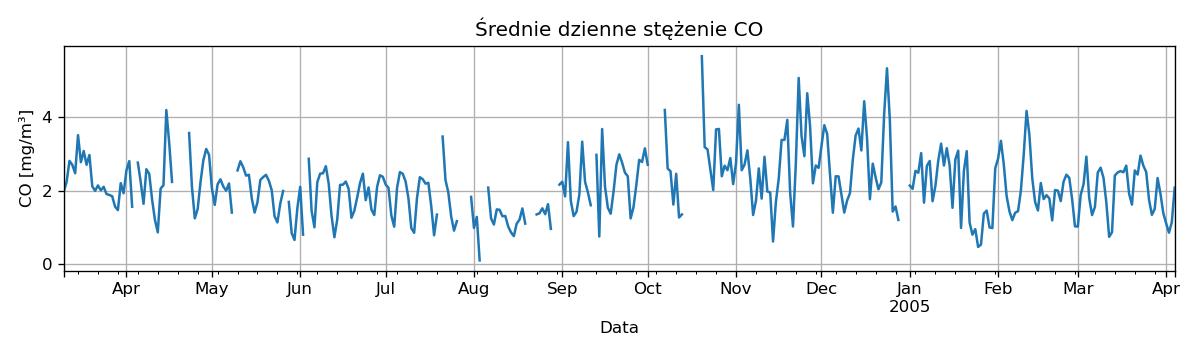

In [2]:
print("Liczba pomiarów:", len(dane))
print("Braki CO:", dane["CO(GT)"].isna().sum())
print(dane["CO(GT)"].agg(["mean", "min", "max"]).round(3))

co.plot(figsize=(10, 3), title="Średnie dzienne stężenie CO", grid=True)
plt.xlabel("Data")
plt.ylabel("CO [mg/m³]")
plt.tight_layout()
plt.show()


## Prognoza na 7 dni
Regresja liniowa przewiduje CO na podstawie numeru dnia. Używam ostatnich 30 dni, aby opisać ostatni trend. Pomijam dni bez pomiarów. Najpierw uczę model na wcześniejszych dniach i sprawdzam go na ostatnich 7 dniach. MAE to średni błąd w mg/m³. Następnie uczę model na całym tym okresie i prognozuję tydzień po końcu zbioru.


MAE na ostatnich 7 dniach: 0.75 mg/m³
Trend ostatnich 30 dni: -0.0137 mg/m³ na dobę
2005-04-05    1.73
2005-04-06    1.72
2005-04-07    1.70
2005-04-08    1.69
2005-04-09    1.68
2005-04-10    1.66
2005-04-11    1.65
Freq: D, Name: Prognoza CO [mg/m³], dtype: float64


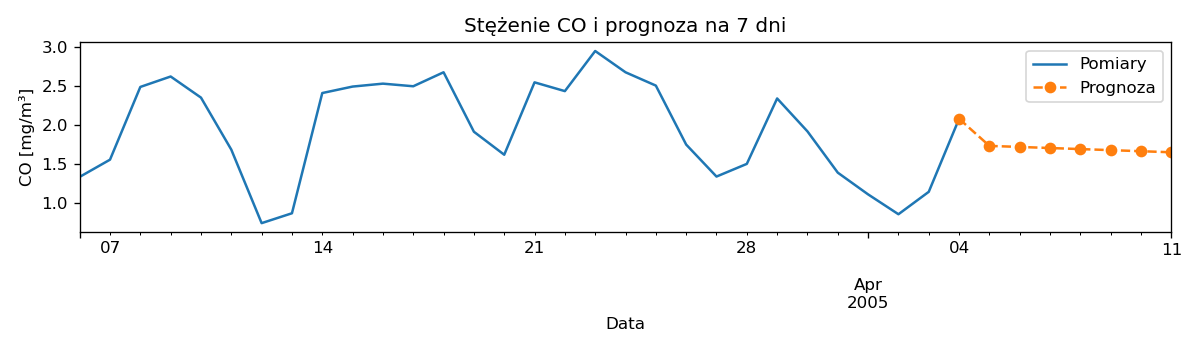

In [3]:
ostatnie = co.loc[co.index >= co.index[-1] - pd.Timedelta(days=29)].dropna()
x = (ostatnie.index - ostatnie.index[0]).days.to_numpy().reshape(-1, 1)

model = LinearRegression()
model.fit(x[:-7], ostatnie.iloc[:-7])
blad = mean_absolute_error(ostatnie.iloc[-7:], model.predict(x[-7:]))
print(f"MAE na ostatnich 7 dniach: {blad:.2f} mg/m³")

model.fit(x, ostatnie)
print(f"Trend ostatnich 30 dni: {model.coef_[0]:+.4f} mg/m³ na dobę")
daty = pd.date_range(co.index[-1] + pd.Timedelta(days=1), periods=7)
x_prognozy = (daty - ostatnie.index[0]).days.to_numpy().reshape(-1, 1)
prognoza = pd.Series(model.predict(x_prognozy), index=daty)
print(prognoza.round(2).rename("Prognoza CO [mg/m³]"))

ostatnie.plot(figsize=(10, 3), label="Pomiary", grid=True)
pd.concat([ostatnie.iloc[-1:], prognoza]).plot(label="Prognoza", style="--o")
plt.title("Stężenie CO i prognoza na 7 dni")
plt.xlabel("Data")
plt.ylabel("CO [mg/m³]")
plt.legend()
plt.tight_layout()
plt.show()


## Wnioski
Średnie stężenie CO wyniosło 2,153 mg/m³, minimum 0,1 mg/m³, a maksimum 11,9 mg/m³.
Trend ostatnich 30 dni wyniósł około -0,0137 mg/m³ na dobę. Model przewiduje niewielki spadek stężenia od 1,73 do 1,65 mg/m³ w dniach 5–11 kwietnia 2005 r.

MAE wyniosło 0,75 mg/m³, więc prognoza jest orientacyjna i nie oddaje nagłych zmian.
W systemie IoT taki wynik może wspomagać planowanie częstszych pomiarów lub ostrzeżeń przy przewidywanym wzroście CO. Decyzje powinny uwzględniać również bieżące odczyty czujników.
